# Report: a one-hidden-layer neural network in NumPy

MAT0611 *Mathematics for Machine Learning*: course project (Anna Spira, Arnould).

This notebook demonstrates `SimpleSLPRegressor` and `SimpleSLPClassifier` (pure NumPy, one hidden layer,
mini-batch gradient descent) and compares them with scikit-learn's `MLPRegressor` / `MLPClassifier`.
Every number below is produced by the code cells; the notebook runs from top to bottom in about a minute.

| Section | Content |
|---|---|
| 0 | Protocol and helper functions |
| 1 | Regression: `load_diabetes` |
| 2 | Binary classification: `load_breast_cancer` |
| 3 | Dataset of our choice: California housing (regression, 20 640 samples) |
| 4 | Bonus: multi-class classification with softmax (`load_iris`, `load_digits`) |
| 5 | Loss curves and analysis: batch size, early stopping, standardization |
| 6 | Summary |

## 0. Protocol

- **Split**: 80 % train / 20 % test, `random_state=42`, stratified for classification (same class proportions in both parts).
- **Feature scaling**: `StandardScaler` is fitted **on the training set only**, then applied to the test set (no information from the test set leaks into training).
- **Target scaling (regression)**: y is standardized with the training mean and standard deviation; predictions are transformed back before computing R² on the original scale.
- **Seeds**: every model gets `random_state=42` (weights, mini-batch order, validation split).
- **Our models**: 30 hidden neurons, mini-batches of 32. Regressor: `learning_rate=0.01`. Classifier: `learning_rate=0.001`.
- **Two scikit-learn references**:
  - *sklearn (Adam)*: default settings (Adam optimizer, L2 penalty `alpha=1e-4`, stops when the training loss stalls), same hidden layer size and same maximum number of epochs;
  - *sklearn (SGD)*: `solver="sgd"`, `momentum=0`, constant learning rate, `alpha=0`, same batch size, automatic stopping disabled. This is **the same algorithm as ours**, so the difference only comes from implementation details (initialization, shuffling).
- **Learning rate for the classifier comparison**: our classifier minimizes the **sum** of the cross-entropy over the batch, sklearn the **mean**. A step of `0.001` on a sum over 32 samples is the same as a step of `0.001 × 32 = 0.032` on the mean, so *sklearn (SGD)* gets `learning_rate_init=0.032`.
- **Loss curves**: our regressor's loss is `1/(2n) Σ (ŷ − y)²`, exactly sklearn's `squared_error` loss, so the curves are directly comparable. Our classifier's loss is a sum over the training set: we divide it by `n_train` to get the mean cross-entropy that sklearn reports.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import (fetch_california_housing, load_breast_cancer, load_diabetes,
                              load_digits, load_iris)
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.preprocessing import StandardScaler

from slp_classifier import SimpleSLPClassifier
from slp_regressor import SimpleSLPRegressor

SEED = 42
HIDDEN = 30
BATCH = 32
ACTIVATIONS = ["relu", "tanh", "logistic"]

# sklearn prints a ConvergenceWarning when it reaches max_iter: we compare at a fixed budget on purpose
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Colors: fixed order, one per model, the same in every figure
COLORS = {"ours relu": "#2a78d6", "ours tanh": "#eb6834", "ours logistic": "#1baf7a",
          "sklearn (Adam)": "#eda100", "sklearn (SGD)": "#e87ba4"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2})
pd.set_option("display.precision", 3)

In [2]:
def split_and_scale(X, y, classification):
    # 80/20 split; the scaler only sees the training set
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, random_state=SEED, stratify=y if classification else None)
    scaler = StandardScaler().fit(X_tr)
    return scaler.transform(X_tr), scaler.transform(X_te), y_tr, y_te


def timed_fit(model, X, y):
    start = time.perf_counter()
    model.fit(X, y)
    return model, time.perf_counter() - start


def compare_regressors(X_tr, X_te, y_tr, y_te, max_iter, learning_rate=0.01):
    # Fit on standardized y, report R² on the original scale
    mu, sd = y_tr.mean(), y_tr.std()
    y_tr_std = (y_tr - mu) / sd
    models = {f"ours {a}": SimpleSLPRegressor(hidden_layer_size=HIDDEN, activation=a,
                                              learning_rate=learning_rate, max_iter=max_iter,
                                              batch_size=BATCH, random_state=SEED)
              for a in ACTIVATIONS}
    models["sklearn (Adam)"] = MLPRegressor(hidden_layer_sizes=(HIDDEN,), max_iter=max_iter,
                                            random_state=SEED)
    models["sklearn (SGD)"] = MLPRegressor(hidden_layer_sizes=(HIDDEN,), solver="sgd", momentum=0,
                                           nesterovs_momentum=False, learning_rate="constant",
                                           learning_rate_init=learning_rate, alpha=0,
                                           batch_size=BATCH, max_iter=max_iter,
                                           n_iter_no_change=max_iter, random_state=SEED)
    rows, curves = [], {}
    for name, model in models.items():
        model, seconds = timed_fit(model, X_tr, y_tr_std)
        rows.append({"model": name,
                     "R² train": r2_score(y_tr, model.predict(X_tr) * sd + mu),
                     "R² test": r2_score(y_te, model.predict(X_te) * sd + mu),
                     "epochs": len(model.loss_curve_), "time (s)": seconds})
        curves[name] = np.asarray(model.loss_curve_)
    return pd.DataFrame(rows).set_index("model"), curves


def compare_classifiers(X_tr, X_te, y_tr, y_te, max_iter, learning_rate=0.001):
    models = {f"ours {a}": SimpleSLPClassifier(hidden_layer_size=HIDDEN, activation=a,
                                               learning_rate=learning_rate, max_iter=max_iter,
                                               batch_size=BATCH, random_state=SEED)
              for a in ACTIVATIONS}
    models["sklearn (Adam)"] = MLPClassifier(hidden_layer_sizes=(HIDDEN,), max_iter=max_iter,
                                             random_state=SEED)
    # Sum over a batch of 32 with step lr == mean with step lr * 32
    models["sklearn (SGD)"] = MLPClassifier(hidden_layer_sizes=(HIDDEN,), solver="sgd", momentum=0,
                                            nesterovs_momentum=False, learning_rate="constant",
                                            learning_rate_init=learning_rate * BATCH, alpha=0,
                                            batch_size=BATCH, max_iter=max_iter,
                                            n_iter_no_change=max_iter, random_state=SEED)
    rows, curves = [], {}
    for name, model in models.items():
        model, seconds = timed_fit(model, X_tr, y_tr)
        curve = np.asarray(model.loss_curve_)
        if name.startswith("ours"):
            curve = curve / len(X_tr)  # summed loss -> mean cross-entropy, like sklearn
        rows.append({"model": name, "accuracy train": model.score(X_tr, y_tr),
                     "accuracy test": model.score(X_te, y_te),
                     "epochs": len(model.loss_curve_), "time (s)": seconds})
        curves[name] = curve
    return pd.DataFrame(rows).set_index("model"), curves


def plot_curves(curves, title, ylabel, ax=None, log=True):
    ax = ax or plt.subplots(figsize=(7, 3.8))[1]
    for name, curve in curves.items():
        ax.plot(np.arange(1, len(curve) + 1), curve, color=COLORS[name], label=name)
    ax.set(title=title, xlabel="epoch", ylabel=ylabel)
    if log:
        ax.set_yscale("log")
    ax.legend(frameon=False)
    return ax

## 1. Regression: `load_diabetes`

442 patients, 10 standardized features (age, sex, BMI, blood pressure, 6 blood measurements); the target is a measure of disease progression one year later (25 to 346). 500 epochs.

In [3]:
X, y = load_diabetes(return_X_y=True)
dia = split_and_scale(X, y, classification=False)
print("train / test:", dia[0].shape, dia[1].shape, "| y range:", y.min(), "-", y.max())

dia_table, dia_curves = compare_regressors(*dia, max_iter=500)

# Linear baseline, for reference
lin = LinearRegression().fit(dia[0], dia[2])
dia_table.loc["linear regression"] = {"R² train": lin.score(dia[0], dia[2]),
                                      "R² test": lin.score(dia[1], dia[3]),
                                      "epochs": np.nan, "time (s)": np.nan}
dia_table

train / test: (353, 10) (89, 10) | y range: 25.0 - 346.0


,R² train,R² test,epochs,time (s)
model,,,,
ours relu,0.652,0.474,500.0,0.171
ours tanh,0.583,0.471,500.0,0.215
ours logistic,0.532,0.469,500.0,0.322
sklearn (Adam),0.690,0.495,500.0,0.139
sklearn (SGD),0.634,0.480,500.0,0.420
linear regression,0.528,0.453,NaN,NaN


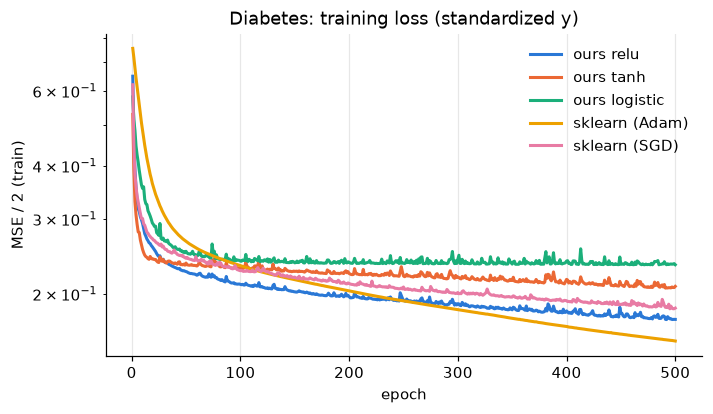

In [4]:
plot_curves(dia_curves, "Diabetes: training loss (standardized y)", "MSE / 2 (train)")
plt.show()

**Reading.** All the networks end with a test R² of the same order, and a plain linear regression is only slightly behind:
diabetes is small (353 training patients) and noisy, and its relation to the target is mostly linear, so a hidden layer has
little to add.
The gap between the train and test R² shows that the networks start to fit the noise of the training set. On the loss curves, our models
and *sklearn (SGD)* (same algorithm) follow similar trajectories; Adam goes down faster thanks to its adaptive step sizes.

## 2. Binary classification: `load_breast_cancer`

569 tumours, 30 features computed from images; target: malignant (0) or benign (1). Sigmoid output, binary cross-entropy. 300 epochs.

In [5]:
X, y = load_breast_cancer(return_X_y=True)
bc = split_and_scale(X, y, classification=True)
print("train / test:", bc[0].shape, bc[1].shape, "| share of benign (train / test):",
      round(bc[2].mean(), 3), "/", round(bc[3].mean(), 3))

bc_table, bc_curves = compare_classifiers(*bc, max_iter=300)
bc_table

train / test: (455, 30) (114, 30) | share of benign (train / test): 0.626 / 0.632


,accuracy train,accuracy test,epochs,time (s)
model,,,,
ours relu,0.993,0.965,300,0.153
ours tanh,0.991,0.947,300,0.192
ours logistic,0.989,0.965,300,0.256
sklearn (Adam),0.991,0.956,300,0.132
sklearn (SGD),0.996,0.947,300,0.349


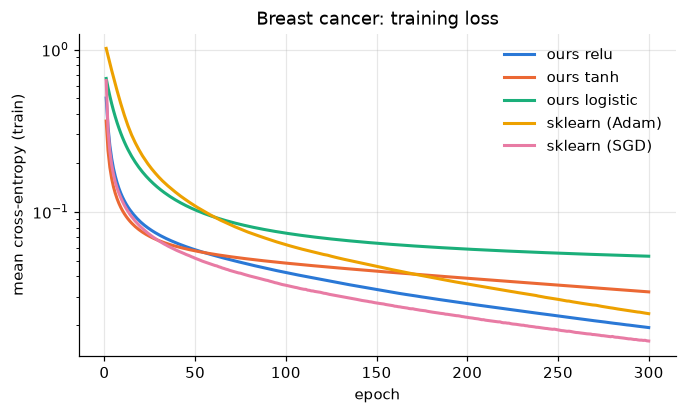

In [6]:
plot_curves(bc_curves, "Breast cancer: training loss", "mean cross-entropy (train)")
plt.show()

In [7]:
# Confusion matrix of our relu model on the test set (rows = true class, columns = predicted)
clf = SimpleSLPClassifier(hidden_layer_size=HIDDEN, activation="relu", learning_rate=0.001,
                          max_iter=300, batch_size=BATCH, random_state=SEED).fit(bc[0], bc[2])
pred = clf.predict(bc[1])
pd.crosstab(pd.Series(bc[3], name="true"), pd.Series(pred, name="predicted"))

predicted,0,1
true,,
0,41,1
1,3,69


**Reading.** The classes are well separated after standardization: every model gets almost all test tumours right, and the
differences between models are one or two test samples (one sample = 1/114 of the accuracy). The training accuracy close to 1 shows
that 30 hidden neurons are more than enough capacity here. In the confusion matrix, the off-diagonal cells are the errors.

## 3. Dataset of our choice: California housing

20 640 districts of California (1990 census), 8 features (median income, house age, rooms, population, location…); target: median house value (in $100 000). This dataset is **47 times larger** than diabetes and more non-linear (location effects), so it shows what the hidden layer adds compared with a linear model. 100 epochs (each epoch is 516 mini-batches).

In [8]:
X, y = fetch_california_housing(return_X_y=True)  # downloaded once by scikit-learn, then cached
cal = split_and_scale(X, y, classification=False)
print("train / test:", cal[0].shape, cal[1].shape)

cal_table, cal_curves = compare_regressors(*cal, max_iter=100)

# Linear baseline: what does the hidden layer bring?
lin = LinearRegression().fit(cal[0], cal[2])
cal_table.loc["linear regression"] = {"R² train": lin.score(cal[0], cal[2]),
                                      "R² test": lin.score(cal[1], cal[3]),
                                      "epochs": np.nan, "time (s)": np.nan}
cal_table

train / test: (16512, 8) (4128, 8)


,R² train,R² test,epochs,time (s)
model,,,,
ours relu,0.758,0.742,100.0,1.430
ours tanh,0.738,0.722,100.0,1.846
ours logistic,0.693,0.673,100.0,2.816
sklearn (Adam),0.763,0.746,100.0,1.097
sklearn (SGD),0.755,0.737,100.0,3.586
linear regression,0.613,0.576,NaN,NaN


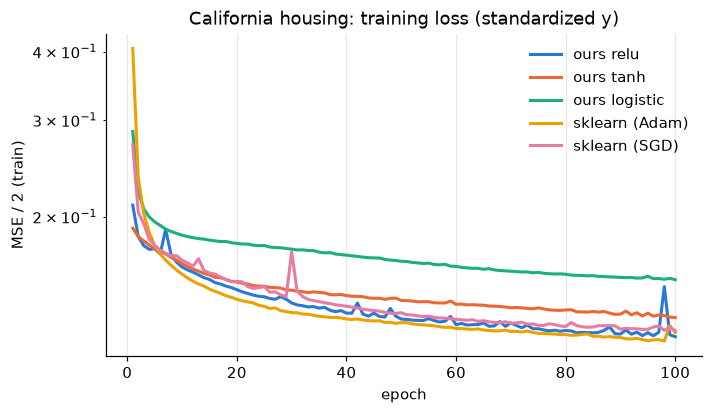

In [9]:
plot_curves(cal_curves, "California housing: training loss (standardized y)", "MSE / 2 (train)")
plt.show()

**Reading.** All the networks beat the linear regression by a wide margin: the hidden layer captures non-linear effects
(for instance, the price does not grow linearly with the location coordinates). With many samples, overfitting is limited
(train and test R² stay close). Within 100 epochs, relu learns fastest and the sigmoid (logistic) slowest: its derivative is at
most 0.25, so its gradients are smaller.

## 4. Bonus: multi-class classification with softmax

With K > 2 classes, the output layer has K neurons followed by a softmax, the labels are one-hot encoded and the loss is the categorical cross-entropy (`dz2 = y_pred − y` again). 300 epochs.
- `load_iris`: 150 flowers, 4 features, 3 species.
- `load_digits`: 1 797 images of 8×8 pixels (64 features), 10 digits.

In [10]:
multi_tables, multi_curves = {}, {}
for name, loader in [("iris", load_iris), ("digits", load_digits)]:
    X, y = loader(return_X_y=True)
    data = split_and_scale(X, y, classification=True)
    multi_tables[name], multi_curves[name] = compare_classifiers(*data, max_iter=300)
    print(name, "train / test:", data[0].shape, data[1].shape, "| classes:", len(np.unique(y)))

pd.concat(multi_tables, names=["dataset"])

iris train / test: (120, 4) (30, 4) | classes: 3


digits train / test: (1437, 64) (360, 64) | classes: 10


accuracy train  accuracy test  epochs  time (s)
dataset model                                                          
iris    ours relu                0.975          0.933     300     0.054
        ours tanh                0.975          0.933     300     0.061
        ours logistic            0.942          0.933     300     0.080
        sklearn (Adam)           0.933          0.867     300     0.046
        sklearn (SGD)            0.975          0.933     300     0.102
digits  ours relu                1.000          0.978     300     0.621
        ours tanh                1.000          0.969     300     0.749
        ours logistic            0.997          0.961     300     0.986
        sklearn (Adam)           1.000          0.978     231     0.505
        sklearn (SGD)            1.000          0.975     300     1.699

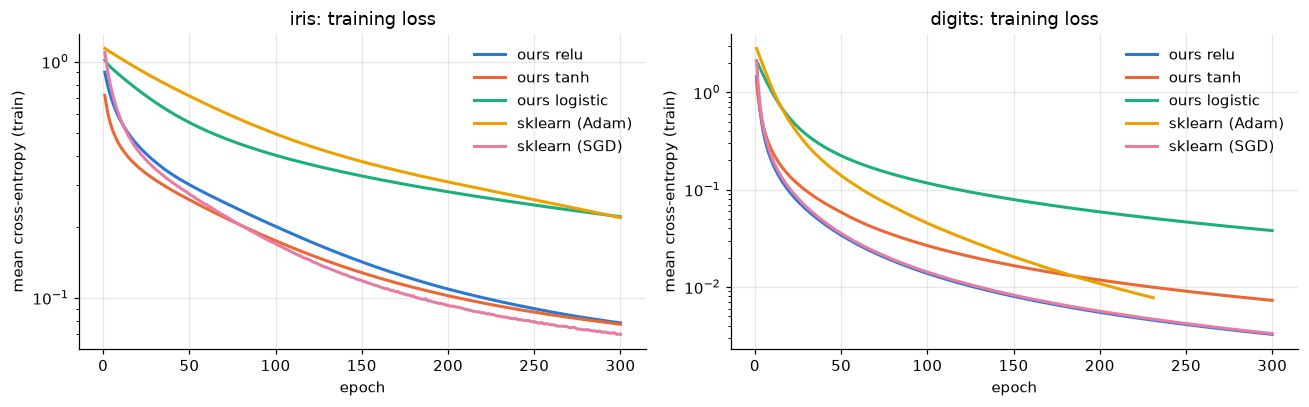

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (name, curves) in zip(axes, multi_curves.items()):
    plot_curves(curves, f"{name}: training loss", "mean cross-entropy (train)", ax=ax)
plt.tight_layout()
plt.show()

**Reading.** The softmax output works for 3 and 10 classes. On iris the test set has only 30 flowers, so one error = 3.3
points: differences between models of one or two samples are not meaningful. *sklearn (Adam)* is lower on iris because it has
not converged in 300 epochs (its default step, 0.001, is small for 4 mini-batches per epoch).

## 5. Analysis

### 5.1 Effect of the batch size

Same model (relu, 30 hidden neurons), same number of epochs, only the batch size changes. One epoch always sees every
training sample once, so the computing cost per epoch is similar; what changes is the **number of weight updates** per
epoch (`ceil(n / batch_size)`).

In [12]:
batch_sizes = [None, 128, 32, 8]  # None = full batch
mu, sd = dia[2].mean(), dia[2].std()
rows, batch_curves = [], {}
for bs in batch_sizes:
    reg, seconds = timed_fit(SimpleSLPRegressor(hidden_layer_size=HIDDEN, activation="relu",
                                                learning_rate=0.01, max_iter=500, batch_size=bs,
                                                random_state=SEED), dia[0], (dia[2] - mu) / sd)
    n_updates = int(np.ceil(len(dia[0]) / (bs or len(dia[0]))))
    rows.append({"batch_size": str(bs), "updates / epoch": n_updates,
                 "final train loss": reg.loss_curve_[-1],
                 "R² test": r2_score(dia[3], reg.predict(dia[1]) * sd + mu), "time (s)": seconds})
    batch_curves[str(bs)] = reg.loss_curve_
pd.DataFrame(rows).set_index("batch_size")

,updates / epoch,final train loss,R² test,time (s)
batch_size,,,,
None,1,0.229,0.479,0.059
128,3,0.205,0.503,0.082
32,12,0.174,0.474,0.174
8,45,0.134,0.289,0.462


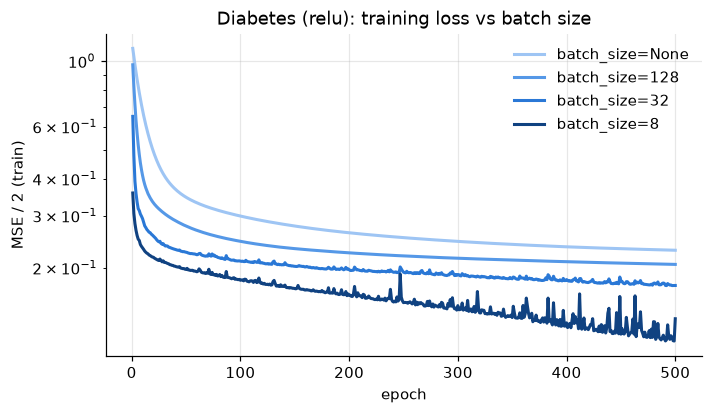

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.8))
blues = ["#9ec5f4", "#5598e7", "#2a78d6", "#104281"]  # one hue, light -> dark = small -> many updates
for color, (bs, curve) in zip(blues, batch_curves.items()):
    ax.plot(np.arange(1, len(curve) + 1), curve, color=color, label=f"batch_size={bs}")
ax.set(title="Diabetes (relu): training loss vs batch size", xlabel="epoch",
       ylabel="MSE / 2 (train)", yscale="log")
ax.legend(frameon=False)
plt.show()

For the **classifier** the batch size has a second effect: its loss is a **sum** over the batch, so the gradient (and the
step) grows with the batch size. With `learning_rate=0.1`, a full batch on breast cancer (455 samples) is like a step of
45.5 on the mean loss, a batch of 8 like a step of 0.8.

In [14]:
rows, clf_batch_curves = [], {}
for bs in batch_sizes:
    clf = SimpleSLPClassifier(hidden_layer_size=HIDDEN, activation="relu", learning_rate=0.1,
                              max_iter=300, batch_size=bs, random_state=SEED)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        np.seterr(all="ignore")  # overflow is expected in the runs that diverge
        clf.fit(bc[0], bc[2])
        np.seterr(all="warn")
    curve = np.asarray(clf.loss_curve_) / len(bc[0])
    rows.append({"batch_size": str(bs), "effective step on the mean loss": 0.1 * (bs or len(bc[0])),
                 "diverged": any("diverged" in str(w.message) for w in caught),
                 "epochs run": clf.n_iter_, "final train loss": curve[-1]})
    clf_batch_curves[str(bs)] = curve
pd.DataFrame(rows).set_index("batch_size")

,effective step on the mean loss,diverged,epochs run,final train loss
batch_size,,,,
None,45.5,True,89,NaN
128,12.8,True,39,NaN
32,3.2,False,300,1.370e-04
8,0.8,False,300,4.338e-05


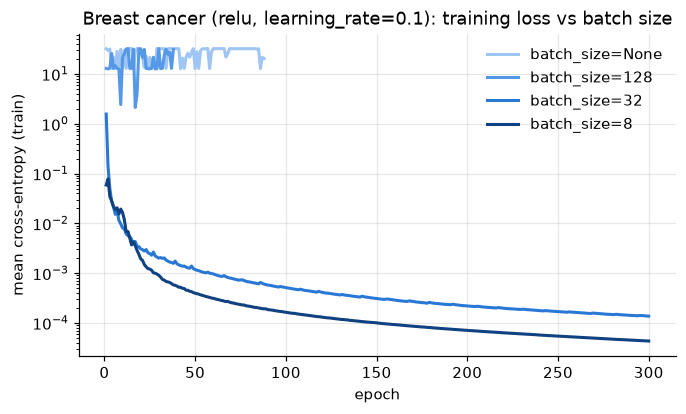

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for color, (bs, curve) in zip(blues, clf_batch_curves.items()):
    ax.plot(np.arange(1, len(curve) + 1), curve, color=color, label=f"batch_size={bs}")
ax.set(title="Breast cancer (relu, learning_rate=0.1): training loss vs batch size",
       xlabel="epoch", ylabel="mean cross-entropy (train)", yscale="log")
ax.legend(frameon=False)
plt.show()

**Reading.**
- *Regressor (mean loss)*: with the same learning rate and the same number of epochs, smaller batches make more updates and
  reach a lower **training** loss. But a lower training loss is not a better model: with batches of 8 (45 updates per epoch,
  22 500 in total) the network fits the noise of the 353 training patients and its test R² drops. Full batch is the slowest to
  train but does not overfit within 500 epochs. Batches of 32 are a good compromise, which is why it is the default.
- *Classifier (summed loss)*: larger batches make **larger** steps. With the same `learning_rate=0.1`, the full batch and the
  batches of 128 diverge (the loss explodes to NaN and our divergence guard stops training), while batches of 32 and 8 converge.
  This is why the classifier uses a smaller learning rate than the regressor, and why the learning rate of a summed loss must
  be chosen together with the batch size. (A diverged model keeps NaN weights and its predictions are meaningless.)

### 5.2 Effect of early stopping

`early_stopping=True` holds out 10 % of the training set, tracks the loss on it after every epoch, stops after 10 epochs
without improvement and **restores the best weights**. To see overfitting clearly we use a large learning rate (0.1) on
diabetes.

In [16]:
rows = []
for lr in [0.01, 0.1]:
    for es in [False, True]:
        reg = SimpleSLPRegressor(hidden_layer_size=HIDDEN, activation="relu", learning_rate=lr,
                                 max_iter=500, batch_size=BATCH, early_stopping=es,
                                 random_state=SEED).fit(dia[0], (dia[2] - mu) / sd)
        rows.append({"learning_rate": lr, "early_stopping": es, "epochs run": reg.n_iter_,
                     "R² train": r2_score(dia[2], reg.predict(dia[0]) * sd + mu),
                     "R² test": r2_score(dia[3], reg.predict(dia[1]) * sd + mu)})
        if lr == 0.1 and es:
            es_model = reg
pd.DataFrame(rows).set_index(["learning_rate", "early_stopping"])

epochs run  R² train  R² test
learning_rate early_stopping                               
0.01          False                  500     0.652    0.474
              True                    50     0.532    0.468
0.10          False                  500     0.639    0.127
              True                    15     0.538    0.477

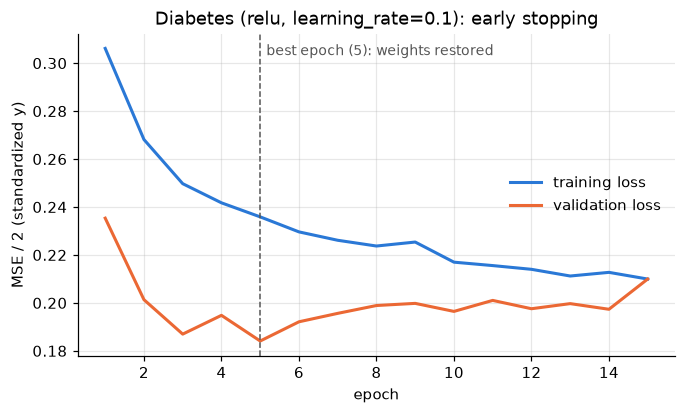

In [17]:
# Train vs validation loss of the early-stopped model (both are means, so they share one axis)
fig, ax = plt.subplots(figsize=(7, 3.8))
epochs = np.arange(1, es_model.n_iter_ + 1)
ax.plot(epochs, es_model.loss_curve_, color="#2a78d6", label="training loss")
ax.plot(epochs, es_model.validation_loss_curve_, color="#eb6834", label="validation loss")
best = int(np.argmin(es_model.validation_loss_curve_)) + 1
ax.axvline(best, color="#555555", linestyle="--", linewidth=1)
ax.annotate(f"best epoch ({best}): weights restored", xy=(best, ax.get_ylim()[1]),
            xytext=(4, -14), textcoords="offset points", fontsize=9, color="#555555")
ax.set(title="Diabetes (relu, learning_rate=0.1): early stopping", xlabel="epoch",
       ylabel="MSE / 2 (standardized y)")
ax.legend(frameon=False, loc="center right")
plt.show()

**Reading.** With `learning_rate=0.1`, the training loss keeps decreasing while the validation loss goes back up after a few
epochs: the model learns the noise of the training set (**overfitting**); without early stopping the train R² keeps rising and the test R² drops.
Early stopping detects this on the validation set, stops, and keeps the best weights. With
`learning_rate=0.01` there is much less overfitting in 500 epochs, so early stopping mostly saves time (far fewer epochs)
for a similar test R².

### 5.3 Effect of standardization

Two experiments: (a) diabetes with the **raw** target (25 to 346) instead of the standardized one; (b) breast cancer with
**raw features** (their scales go from 0.001 to more than 4 000) instead of standardized ones.

In [18]:
X, y = load_diabetes(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
scaler = StandardScaler().fit(X_tr)
X_tr, X_te = scaler.transform(X_tr), scaler.transform(X_te)
mu, sd = y_tr.mean(), y_tr.std()

rows = []
for act in ACTIVATIONS:
    for target in ["raw y", "standardized y"]:
        reg = SimpleSLPRegressor(hidden_layer_size=HIDDEN, activation=act, learning_rate=0.01,
                                 max_iter=500, batch_size=BATCH, random_state=SEED)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            np.seterr(all="ignore")  # overflow is expected in the raw-y runs
            if target == "raw y":
                reg.fit(X_tr, y_tr)
                pred = reg.predict(X_te)
            else:
                reg.fit(X_tr, (y_tr - mu) / sd)
                pred = reg.predict(X_te) * sd + mu
            np.seterr(all="warn")
        finite = np.all(np.isfinite(pred))
        rows.append({"activation": act, "target": target,
                     "diverged": any("diverged" in str(w.message) for w in caught),
                     "epochs run": reg.n_iter_,
                     "R² test": r2_score(y_te, pred) if finite else np.nan})
pd.DataFrame(rows).set_index(["activation", "target"])

diverged  epochs run  R² test
activation target                                       
relu       raw y               True           1      NaN
           standardized y     False         500    0.474
tanh       raw y              False         500    0.407
           standardized y     False         500    0.471
logistic   raw y              False         500    0.390
           standardized y     False         500    0.469

In [19]:
X, y = load_breast_cancer(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print("feature scales (raw): min of column means =", X_tr.mean(axis=0).min().round(4),
      "| max of column means =", X_tr.mean(axis=0).max().round(1))
scaler = StandardScaler().fit(X_tr)

rows = []
for act in ACTIVATIONS:
    for features in ["raw X", "standardized X"]:
        A_tr, A_te = (X_tr, X_te) if features == "raw X" else (scaler.transform(X_tr), scaler.transform(X_te))
        clf = SimpleSLPClassifier(hidden_layer_size=HIDDEN, activation=act, learning_rate=0.001,
                                  max_iter=300, batch_size=BATCH, random_state=SEED)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            np.seterr(all="ignore")
            clf.fit(A_tr, y_tr)
            np.seterr(all="warn")
        rows.append({"activation": act, "features": features,
                     "accuracy test": clf.score(A_te, y_te)})
print("share of the majority class in the test set:", round(max(y_te.mean(), 1 - y_te.mean()), 3))
pd.DataFrame(rows).set_index(["activation", "features"])

feature scales (raw): min of column means = 0.0038 | max of column means = 869.0


share of the majority class in the test set: 0.632


accuracy test
activation features                     
relu       raw X                   0.632
           standardized X          0.965
tanh       raw X                   0.632
           standardized X          0.947
logistic   raw X                   0.632
           standardized X          0.965

**Reading.**
- *Raw target*: the output error `ŷ − y` starts around 150, so `dz2` and therefore every gradient step is about 150 times
  larger than with a standardized target. Depending on the activation, training diverges (our divergence guard stops it and
  warns) or ends far from the optimum. With a standardized target the same settings work. This is the project tip
  "standardize continuous targets".
- *Raw features*: with features of order 1 000, `z1 = X @ W1 + b1` is huge: sigmoid and tanh **saturate** (derivative ≈ 0,
  no learning), and relu takes enormous steps. With raw features all three models end up predicting the same class for every
  tumour: their accuracy equals the share of the majority class printed above. Standardization puts every feature on the same
  scale, so no feature dominates the gradient and the activations work in their useful range.

## 6. Summary

In [20]:
summary = pd.DataFrame({
    "diabetes (R²)": dia_table["R² test"],
    "California (R²)": cal_table["R² test"].drop("linear regression"),
    "breast cancer (acc.)": bc_table["accuracy test"],
    "iris (acc.)": multi_tables["iris"]["accuracy test"],
    "digits (acc.)": multi_tables["digits"]["accuracy test"],
})
summary

,diabetes (R²),California (R²),breast cancer (acc.),iris (acc.),digits (acc.)
model,,,,,
linear regression,0.453,NaN,NaN,NaN,NaN
ours logistic,0.469,0.673,0.965,0.933,0.961
ours relu,0.474,0.742,0.965,0.933,0.978
ours tanh,0.471,0.722,0.947,0.933,0.969
sklearn (Adam),0.495,0.746,0.956,0.867,0.978
sklearn (SGD),0.480,0.737,0.947,0.933,0.975


**Conclusions.**
- Our NumPy implementation (forward pass, backpropagation, mini-batch gradient descent) reaches scores of the same order as
  scikit-learn on every dataset, both against *sklearn (SGD)* (the same algorithm) and against *sklearn (Adam)* (a stronger
  optimizer).
- The three hidden activations give close results on the small datasets. On California housing, with a fixed budget of 100
  epochs, relu is best and the sigmoid is slowest to converge (its derivative is at most 0.25). Relu is also the cheapest to compute.
- Preprocessing matters as much as the model: without standardization of X (classification) or of y (regression), the same
  network saturates or diverges.
- The batch size and the learning rate must be chosen together, especially for the classifier, whose summed loss makes the step
  grow with the batch size.
- Early stopping prevents overfitting when the learning rate is large, and saves epochs otherwise.